# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = "/home/fra/Documenti/BIC/Brazialian_Ecomm/data_processed/"

orders_full = pd.read_parquet(path + "orders_full.parquet")
items_full = pd.read_parquet(path + "items_full.parquet")

### Data Overview and Validation

In [4]:
for name, df in {"orders_full": orders_full, "items_full": items_full}.items():
    print(f"\n{name}: {df.shape}")
    df.info()


orders_full: (99441, 22)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
 8   customer_unique_id             99441 non-null  str           
 9   customer_zip_code_prefix       99441 non-null  str           
 10  customer_city                  99441 non-null  str           
 11  

In [6]:
# check duplicates in keys keys
print(orders_full["order_id"].duplicated().sum())
print(items_full.duplicated(subset=["order_id", "order_item_id"]).sum())

0
0


In [8]:
# Check for NaN
orders_full.isna().sum()

order_id                             0
customer_id                          0
order_status                         0
order_purchase_timestamp             0
order_approved_at                  160
order_delivered_carrier_date      1783
order_delivered_customer_date     2965
order_estimated_delivery_date        0
customer_unique_id                   0
customer_zip_code_prefix             0
customer_city                        0
customer_state                       0
items_value                        775
freight_value                      775
n_items                            775
n_sellers                          775
review_id                          768
review_score                       768
review_comment_title             87890
review_comment_message           58658
review_creation_date               768
review_answer_timestamp            768
dtype: int64

In [9]:
items_full.isna().sum()

order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
product_category_name            0
product_name_lenght           1603
product_description_lenght    1603
product_photos_qty            1603
product_weight_g                18
product_length_cm               18
product_height_cm               18
product_width_cm                18
seller_zip_code_prefix           0
seller_city                      0
seller_state                     0
dtype: int64

In [10]:
# Time-span
orders_full["order_purchase_timestamp"].agg(["min", "max"])

min   2016-09-04 21:15:19
max   2018-10-17 17:30:18
Name: order_purchase_timestamp, dtype: datetime64[us]

In [11]:
# Status distribution
orders_full["order_status"].value_counts(normalize=True).mul(100).round(2)

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

### Delivery metrics and Analysis sample

In [12]:
# Delivered items only
delivered = orders_full[orders_full["order_status"] == "delivered"]
delivered.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,items_value,freight_value,n_items,n_sellers,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,03149,...,29.99,8.72,1.0,1.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,118.70,22.76,1.0,1.0,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,159.90,19.22,1.0,1.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,45.00,27.20,1.0,1.0,359d03e676b3c069f62cadba8dd3f6e8,5.0,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,09195,...,19.90,8.72,1.0,1.0,e50934924e227544ba8246aeb3770dd4,5.0,NaN,NaN,2018-02-17,2018-02-18 13:02:51


In [13]:
delivered.isna().sum()

order_id                             0
customer_id                          0
order_status                         0
order_purchase_timestamp             0
order_approved_at                   14
order_delivered_carrier_date         2
order_delivered_customer_date        8
order_estimated_delivery_date        0
customer_unique_id                   0
customer_zip_code_prefix             0
customer_city                        0
customer_state                       0
items_value                          0
freight_value                        0
n_items                              0
n_sellers                            0
review_id                          646
review_score                       646
review_comment_title             85287
review_comment_message           57565
review_creation_date               646
review_answer_timestamp            646
dtype: int64

In [ ]:
# dropping NaN in delivered

In [14]:
date_cols = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

delivered.dropna(subset = date_cols, inplace = True)

In [16]:
# delivery time

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds()/ 86400

In [17]:
delivered.loc[delivered["delivery_days"] < 0, ["order_id"] + date_cols]

,order_id,order_delivered_customer_date,order_estimated_delivery_date


There are no incongruent times (negative)

In [18]:
# delay days
delivered["delay_days"] = (
    delivered["order_delivered_customer_date"].dt.normalize()
    - delivered["order_estimated_delivery_date"].dt.normalize()
).dt.days

delivered["is_late"] = delivered["delay_days"] > 0

In [19]:
delivered.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,n_sellers,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,delivery_days,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,03149,...,1.0,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48,8.436574,-8,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,1.0,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08,2018-08-08 18:37:50,13.782037,-6,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18,2018-08-22 19:07:58,9.394213,-18,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,1.0,359d03e676b3c069f62cadba8dd3f6e8,5.0,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03,2017-12-05 19:21:58,13.208750,-13,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,09195,...,1.0,e50934924e227544ba8246aeb3770dd4,5.0,NaN,NaN,2018-02-17,2018-02-18 13:02:51,2.873877,-10,False


In [ ]:
# Check for extreme values

In [20]:
delivered["delay_group"] = pd.cut(
    delivered["delay_days"],
    bins=[-float("inf"), 0, 3, 7, float("inf")],
    labels=["On time", "1–3 days", "4–7 days", "Over 7 days"]
)

In [21]:
delivered[["delivery_days", "delay_days"]].describe(
    percentiles=[0.5, 0.9, 0.99]
)

,delivery_days,delay_days
count,96470.000000,96470.000000
mean,12.558217,-11.875889
std,9.546156,10.182105
min,0.533414,-147.000000
50%,10.217477,-12.000000
90%,23.096377,-2.000000
99%,46.050262,18.000000
max,209.628611,188.000000


In [25]:
delivered.nlargest(10, "delivery_days")[
    ["order_id", "delivery_days", "delay_days"] + date_cols
]

,order_id,delivery_days,delay_days,order_delivered_customer_date,order_estimated_delivery_date
19590,ca07593549f1816d26a572e06dc1eab6,209.628611,181,2017-09-19 14:36:39,2017-03-22
55619,1b3190b2dfa9d789e1f14c05b647a14a,208.351759,188,2018-09-19 23:24:07,2018-03-15
61610,440d0d17af552815d15a9e41abe49359,195.634016,165,2017-09-19 15:12:50,2017-04-07
70307,2fb597c2f772eca01b1f5c561bf6cc7b,194.850174,155,2017-09-19 14:33:17,2017-04-17
89130,285ab9426d6982034523a855f55a885e,194.633611,166,2017-09-19 14:00:04,2017-04-06
38509,0f4519c5f1c541ddec9f21b3bddd533a,194.049583,161,2017-09-19 14:38:21,2017-04-11
11399,47b40429ed8cce3aee9199792275433f,191.463542,175,2018-07-13 20:51:31,2018-01-19
81401,2fe324febf907e3ea3f2aa9650869fa5,189.863160,167,2017-09-19 17:00:07,2017-04-05
54480,2d7561026d542c8dbd8f0daeadf67a43,188.134618,159,2017-09-19 14:38:18,2017-04-13
68769,c27815f7e3dd0b926b58552628481575,187.743843,162,2017-09-19 17:14:25,2017-04-10


The 10 longest delivery times are between 187 and 210 days, with delays of 155–188 days beyond the estimated time.
8 of these orders share the delivery date September 19, 2017. This clustering may indicate a batch update or a data quality issue, although the cause cannot be confirmed. These records are retained and flagged for further investigation.

### Delivery performance

In [26]:
summary = pd.Series({
    "Delivered orders": len(delivered),
    "Late deliveries (%)": delivered["is_late"].mean() * 100,
    "Median delivery days": delivered["delivery_days"].median(),
    "90th percentile delivery days": delivered["delivery_days"].quantile(0.90)
})

summary.round(2)

Delivered orders                 96470.00
Late deliveries (%)                  6.77
Median delivery days                10.22
90th percentile delivery days       23.10
dtype: float64

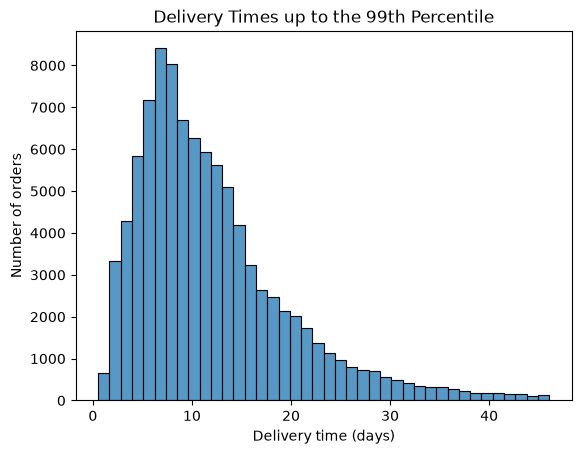

In [30]:
limit = delivered["delivery_days"].quantile(0.99)

sns.histplot(
    data=delivered.loc[delivered["delivery_days"] <= limit],
    x="delivery_days",
    bins=40
)
plt.title("Delivery Times up to the 99th Percentile")
plt.xlabel("Delivery time (days)")
plt.ylabel("Number of orders")
plt.show()

In [31]:
percentages = (
    delivered["is_late"]
    .value_counts(normalize=True)
    .reindex([False, True], fill_value=0)
    .mul(100)
)
percentages.index = ["On time", "Late"]

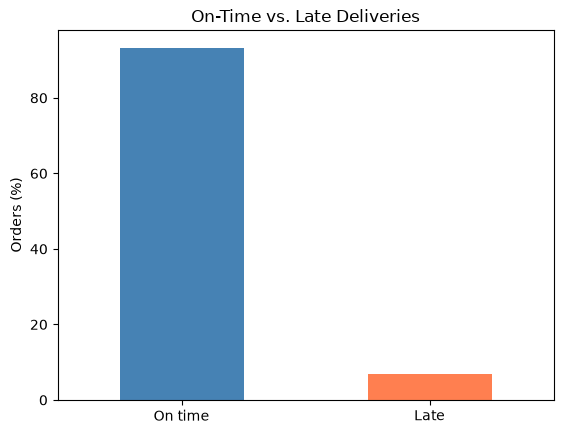

In [32]:
percentages.plot.bar(rot=0, color=["steelblue", "coral"])
plt.title("On-Time vs. Late Deliveries")
plt.ylabel("Orders (%)")
plt.show()

Most orders arrived on time (93.23%). Median delivery time was 10.22 days, while 90% of orders arrived within 23.10 days.

### Delays and Satisfaction

In [44]:
# remove null reviews for this analysis
reviews = delivered.dropna(subset = ["review_score"]).copy()
print(reviews.shape)

(95824, 26)


In [45]:
reviews["review_before_delivery"] = (
    reviews["review_answer_timestamp"]
    < reviews["order_delivered_customer_date"]
)

reviews["review_before_delivery"].value_counts()

review_before_delivery
False    91121
True      4703
Name: count, dtype: int64

In [52]:
review_before_delivery = (
    reviews["review_before_delivery"].value_counts(normalize = True)
    .reindex([False, True], fill_value = 0).mul(100)
)
review_before_delivery.index = ["After delivery", "Before delivery"]
review_before_delivery

After delivery     95.092044
Before delivery     4.907956
Name: proportion, dtype: float64

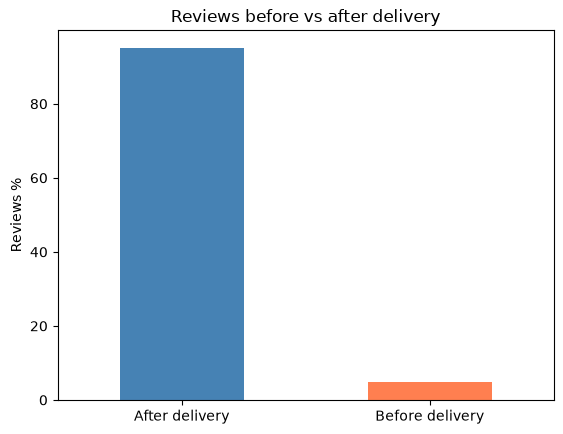

In [53]:
review_before_delivery.plot.bar(rot=0, color = ["steelblue", "coral"])
plt.title("Reviews before vs after delivery")
plt.ylabel("Reviews %")
plt.show()

Low ratings became more frequent as delays increased: from 9.27% for on-time orders to 79.18% for delays exceeding seven days. This association does not establish causality.

In [54]:
comparison = reviews.groupby("is_late").agg(
    n_reviews=("review_score", "count"),
    average_score=("review_score", "mean"),
    low_score_pct=("review_score", lambda x: x.le(2).mean() * 100)
)

comparison.round(2)

,n_reviews,average_score,low_score_pct
is_late,,,
False,89443,4.29,9.27
True,6381,2.27,62.37


In [55]:
delay_summary = reviews.groupby("delay_group", observed=True).agg(
    n_reviews=("review_score", "count"),
    average_score=("review_score", "mean"),
    low_score_pct=("review_score", lambda x: x.le(2).mean() * 100)
)

delay_summary.round(2)

,n_reviews,average_score,low_score_pct
delay_group,,,
On time,89443,4.29,9.27
1–3 days,1852,3.29,32.18
4–7 days,1748,2.10,67.62
Over 7 days,2781,1.70,79.18


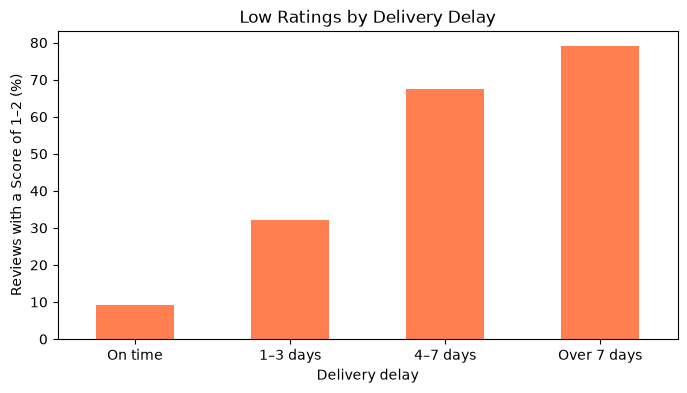

In [56]:
delay_summary["low_score_pct"].plot.bar(
    rot=0, color="coral", figsize=(8, 4)
)
plt.title("Low Ratings by Delivery Delay")
plt.xlabel("Delivery delay")
plt.ylabel("Reviews with a Score of 1–2 (%)")
plt.show()

### Geographic and Temporal Patterns

In [59]:
state_summary = delivered.groupby("customer_state").agg(
    n_orders=("order_id", "count"),
    late_pct=("is_late", lambda x: x.mean() * 100),
    median_delivery_days=("delivery_days", "median")
)

state_summary.round(2).head(10)

,n_orders,late_pct,median_delivery_days
customer_state,,,
AC,80,3.75,18.36
AL,397,21.41,22.33
AM,145,2.76,25.88
AP,67,2.99,24.35
BA,3256,12.16,16.91
CE,1279,13.76,18.21
DF,2080,5.67,11.36
ES,1995,10.73,13.64
GO,1957,6.54,13.95


Late-delivery rates varied across customer states. Monthly comparisons require caution because some months contain very few orders or cover incomplete periods.

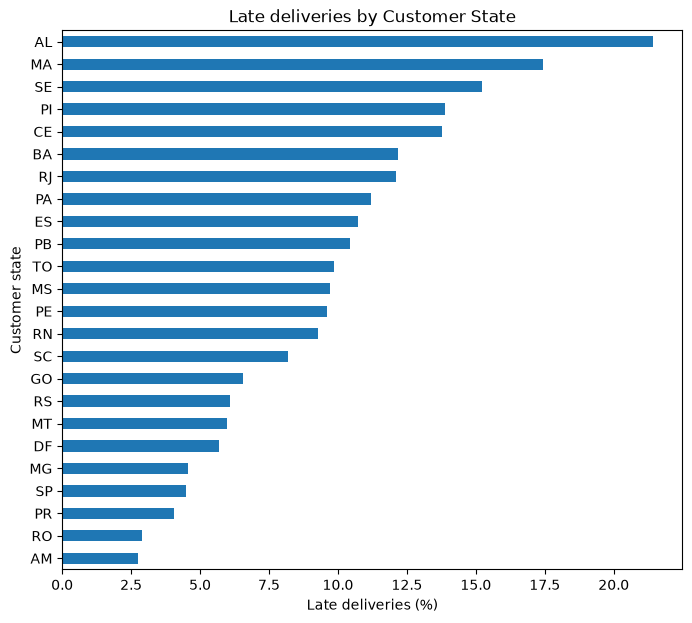

In [60]:
state_summary.query("n_orders >= 100").sort_values(
    "late_pct"
)["late_pct"].plot.barh(figsize=(8, 7))

plt.title("Late deliveries by Customer State")
plt.xlabel("Late deliveries (%)")
plt.ylabel("Customer state")
plt.show()

In [62]:
delivered["purchase_month"] = (
    delivered["order_purchase_timestamp"].dt.to_period("M")
)

monthly = delivered.groupby("purchase_month").agg(
    n_orders=("order_id", "count"),
    late_pct=("is_late", lambda x: x.mean() * 100),
    median_delivery_days=("delivery_days", "median")
)

monthly.round(2).head(10)

,n_orders,late_pct,median_delivery_days
purchase_month,,,
2016-09,1,100.00,54.81
2016-10,265,0.75,17.94
2016-12,1,0.00,4.69
2017-01,750,2.93,10.73
2017-02,1653,2.96,10.97
2017-03,2546,4.56,10.13
2017-04,2303,6.56,12.75
2017-05,3545,2.99,9.79
2017-06,3135,3.03,10.80


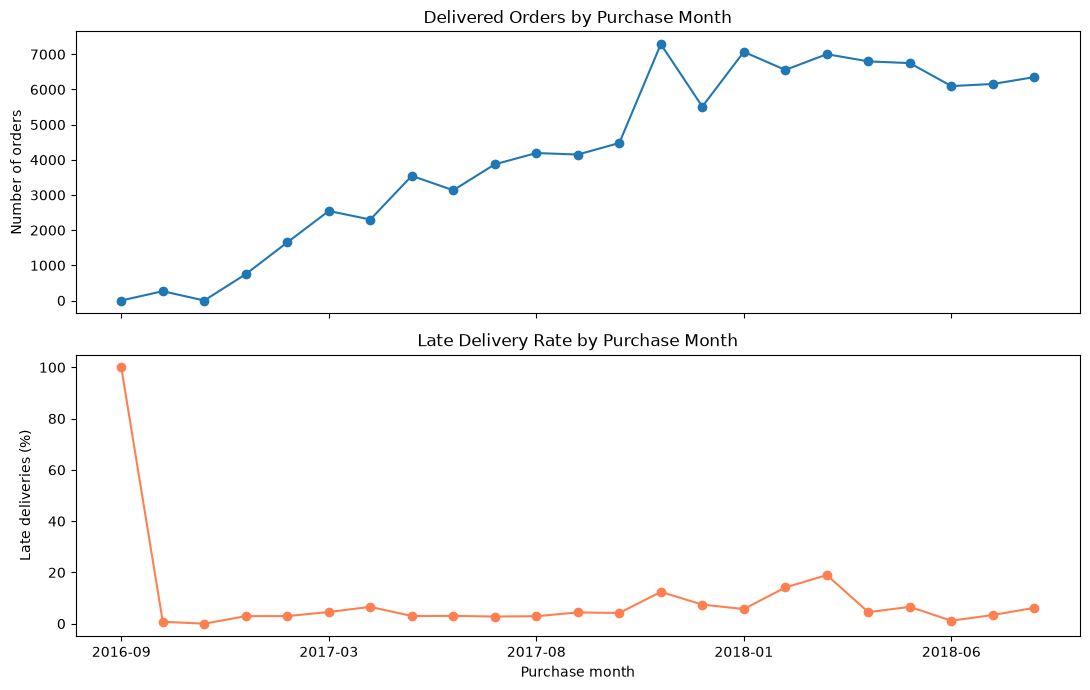

In [63]:
monthly_plot = monthly.copy()
monthly_plot.index = monthly_plot.index.astype(str)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

monthly_plot["n_orders"].plot(ax=axes[0], marker="o")
axes[0].set_title("Delivered Orders by Purchase Month")
axes[0].set_ylabel("Number of orders")

monthly_plot["late_pct"].plot(ax=axes[1], marker="o", color="coral")
axes[1].set_title("Late Delivery Rate by Purchase Month")
axes[1].set_ylabel("Late deliveries (%)")
axes[1].set_xlabel("Purchase month")

plt.tight_layout()
plt.show()

### Product and Seller Analysis

In [65]:
analysis_items = items_full.merge(
    delivered[["order_id", "is_late", "delivery_days"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

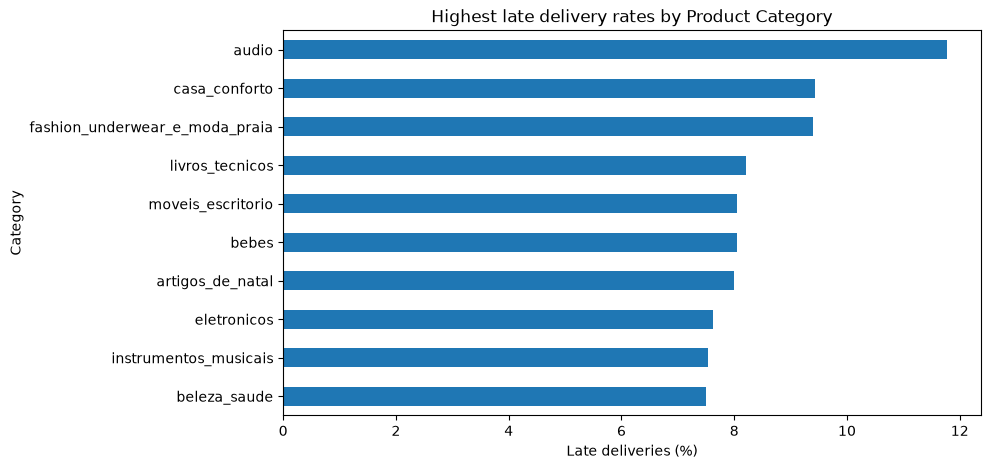

In [67]:
category_orders = analysis_items.drop_duplicates(
    subset=["order_id", "product_category_name"]
)

category_summary = category_orders.groupby("product_category_name").agg(
    n_orders=("order_id", "count"),
    late_pct=("is_late", lambda x: x.mean() * 100)
)

category_summary.query("n_orders >= 100").sort_values(
    "late_pct"
).tail(10)["late_pct"].plot.barh(figsize=(9, 5))

plt.title("Highest late delivery rates by Product Category")
plt.xlabel("Late deliveries (%)")
plt.ylabel("Category")
plt.show()

In [69]:
seller_count = items_full.groupby("order_id")["seller_id"].nunique()
single_seller_ids = seller_count[seller_count.eq(1)].index

seller_orders = (
    analysis_items[
        analysis_items["order_id"].isin(single_seller_ids)
    ]
    .drop_duplicates(subset=["order_id", "seller_id"])
)

seller_summary = seller_orders.groupby("seller_id").agg(
    n_orders=("order_id", "count"),
    late_pct=("is_late", lambda x: x.mean() * 100),
    median_delivery_days=("delivery_days", "median")
)

seller_summary.query("n_orders >= 50").sort_values(
    "late_pct", ascending=False
).head(10).round(2)

,n_orders,late_pct,median_delivery_days
seller_id,,,
54965bbe3e4f07ae045b90b0b8541f52,72,30.56,16.63
beadbee30901a7f61d031b6b686095ad,63,23.81,9.60
a49928bcdf77c55c6d6e05e09a9b4ca5,93,22.58,14.00
712e6ed8aa4aa1fa65dab41fed5737e4,77,20.78,16.20
d20b021d3efdf267a402c402a48ea64b,73,19.18,14.70
06a2c3af7b3aee5d69171b0e14f0ee87,388,19.07,15.77
88460e8ebdecbfecb5f9601833981930,227,18.50,15.81
ea566164622c6b439516ab18062c42cd,50,18.00,9.92
6039e27294dc75811c0d8a39069f52c0,62,17.74,15.42


## Key Findings, Recommendations and Limitations

### Key Findings
- Among **96,470** delivered orders with valid dates, **6.77%** arrived late. Median delivery time was **10.22** days, while **90%** arrived within **23.10** days.
- Late orders received an average review score of **2.27**, compared with **4.29** for on-time orders.
- Low ratings (1–2) accounted for **62.37%** of late-order reviews versus **9.27%** of on-time reviews, rising to **79.18%** for delays exceeding seven days.
- Geographic differences were substantial: Alagoas recorded a **21.41%** late-delivery rate across **397** orders.

### Business Recommendations
- Investigate logistics routes and seller groups with elevated delay rates, prioritizing those with substantial order volumes.
- Introduce proactive customer updates when deliveries exceed the promised date, particularly for prolonged delays.

### Limitations
- These associations do not establish that delays cause low ratings.
- Delivery metrics exclude undelivered orders and records without the required dates.
- Some reviews were submitted before delivery and may reflect the waiting experience.
- Extreme delivery times and suspicious date clustering remain unresolved.
- Geographic and seller comparisons do not control for differences in product mix, destination, or purchase period.

In [71]:
from pathlib import Path

output = Path(path + "/Results")
output.mkdir(parents=True, exist_ok=True)

delivery_export = delivered.copy()

delivery_export["purchase_month"] = (
    delivery_export["purchase_month"].dt.to_timestamp()
)

delivery_export.to_parquet(
    output / "delivery_analysis.parquet", index=False
)
delivery_export.to_csv(
    output / "delivery_analysis.csv", index=False
)

# Recap
tables = {
    "delivery_performance": summary.rename_axis("metric").reset_index(name="value"),
    "reviews_by_delivery_status": comparison.reset_index(),
    "reviews_by_delay_group": delay_summary.reset_index(),
    "delivery_by_state": state_summary.reset_index(),
    "delivery_by_month": monthly.reset_index(),
    "delivery_by_category": category_summary.reset_index(),
    "delivery_by_seller": seller_summary.reset_index()
}

tables["delivery_by_month"]["purchase_month"] = (
    tables["delivery_by_month"]["purchase_month"].dt.to_timestamp()
)

for name, table in tables.items():
    table.to_csv(output / f"{name}.csv", index=False)